# Mini-Project 2 — Solar Micro-Grid Dispatch Planner (Kasese health centre)

Each day the solar energy *x* and battery energy *y* (kWh) must satisfy

$$3x + 2y = D_1 \quad\text{(daytime load)} \qquad 4x + y = D_2 \quad\text{(critical-equipment load)}$$

The system is modelled by `MicroGrid` (and the 3-source `HybridMicroGrid`) in `src/microgrid.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)
import timeit
from src.microgrid import (MicroGrid, HybridMicroGrid, prompt_positive_float,
                           generate_demand_csv, load_demand_csv)

## 1. Is the system well-posed?

In [2]:
grid = MicroGrid()
print(grid)
print("A =\n", grid.A)
print(f"det(A)  = {grid.determinant():.3f}   (hand: 3·1 − 2·4 = −5)")
print(f"cond(A) = {grid.condition_number():.3f}")
print("Inverse:\n", np.linalg.inv(grid.A))
print("Example: D1 = 40, D2 = 45  →", grid.solve_day(40, 45), "(hand: x = 10, y = 5)")

MicroGrid(n_sources=2, det=-5)
A =
 [[3. 2.]
 [4. 1.]]
det(A)  = -5.000   (hand: 3·1 − 2·4 = −5)
cond(A) = 5.828
Inverse:
 [[-0.2  0.4]
 [ 0.8 -0.6]]
Example: D1 = 40, D2 = 45  → [10.  5.] (hand: x = 10, y = 5)


* **Determinant = −5 ≠ 0**, so the two constraint lines are not parallel and there is exactly one (x, y) for every
  (D₁, D₂). The sign only reflects row order; its magnitude being well away from 0 is what matters.
* **Condition number ≈ 5.8** (2-norm: ratio of the largest to smallest singular value). It bounds how much a
  relative error in the demand can be amplified in the solution: a 1 % error in D could become at most ~5.8 %
  in (x, y). Values near 1 are perfect, values above ~10⁶ are trouble in double precision; 5.8 means the system is
  well-conditioned and we lose under one significant digit.
* Closed form: x = (2D₂ − D₁)/5, y = (4D₁ − 3D₂)/5. So **both sources are non-negative only if
  D₁/2 ≤ D₂ ≤ 4D₁/3** — this inequality explains every infeasible day found below.

## 2. Input modes

**(a) Interactive.** `prompt_positive_float` re-prompts on empty, non-numeric, negative and non-finite input.
To keep *Restart & Run All* non-blocking, the notebook feeds it a scripted list of typed answers; set
`INTERACTIVE = True` to type them yourself.

In [3]:
INTERACTIVE = False

if INTERACTIVE:
    d1 = prompt_positive_float("Daytime load D1 (kWh): ")
    d2 = prompt_positive_float("Critical load D2 (kWh): ")
else:
    typed = iter(["", "sixty", "-12", "62.5",      # D1: empty, text, negative, then valid
                  "70"])                           # D2: valid first time
    fake_input = lambda msg: (lambda v: (print(msg + repr(v)), v)[1])(next(typed))
    d1 = prompt_positive_float("Daytime load D1 (kWh): ", input_func=fake_input)
    d2 = prompt_positive_float("Critical load D2 (kWh): ", input_func=fake_input)
x, y = grid.solve_day(d1, d2)
print(f"\nD1={d1}, D2={d2} → solar x = {x:.2f} kWh, battery y = {y:.2f} kWh")

Daytime load D1 (kWh): ''
  ✗ Empty input — please type a number.
Daytime load D1 (kWh): 'sixty'
  ✗ 'sixty' is not a number.
Daytime load D1 (kWh): '-12'
  ✗ Demand must be a non-negative, finite number.
Daytime load D1 (kWh): '62.5'
Critical load D2 (kWh): '70'

D1=62.5, D2=70.0 → solar x = 15.50 kWh, battery y = 8.00 kWh


**(b) CSV.** 30 days generated with `np.random.default_rng(2026)`: D₁ ≈ 60 kWh with a weekday/weekend cycle
(outpatient clinics run on weekdays) plus Gaussian noise; D₂ ≈ 1.1 × D₁ plus independent noise (fridges for
vaccines, oxygen concentrators and theatre lighting track overall activity, but not perfectly).

In [4]:
csv_path = DATA / "kasese_demand.csv"
demand_df = generate_demand_csv(csv_path, days=30, seed=SEED)
D = load_demand_csv(csv_path)          # shape (2, 30)
print("Saved", csv_path.relative_to(ROOT), "| shape", D.shape)
demand_df.head(8)

Saved data/kasese_demand.csv | shape (2, 30)


,day,date,D1_kWh,D2_kWh
0,1,2026-09-01,63.620,65.300
1,2,2026-09-02,68.680,80.950
2,3,2026-09-03,62.750,72.360
3,4,2026-09-04,71.270,82.950
4,5,2026-09-05,66.830,69.970
5,6,2026-09-06,52.690,60.690
6,7,2026-09-07,53.110,56.340
7,8,2026-09-08,66.910,71.770


## 3. Loop vs vectorised solve

In [5]:
loop_sol = grid.solve_loop(D)
vec_sol = grid.solve_vectorised(D)
assert np.allclose(loop_sol, vec_sol)

N_REP = 2000
t_loop = timeit.timeit(lambda: grid.solve_loop(D), number=N_REP) / N_REP
t_vec = timeit.timeit(lambda: grid.solve_vectorised(D), number=N_REP) / N_REP
print(f"Loop      : {t_loop*1e6:8.1f} µs per 30-day solve")
print(f"Vectorised: {t_vec*1e6:8.1f} µs per 30-day solve")
print(f"Speed-up  : {t_loop/t_vec:.1f}×  (identical results: {np.allclose(loop_sol, vec_sol)})")

Loop      :    867.9 µs per 30-day solve
Vectorised:     60.1 µs per 30-day solve
Speed-up  : 14.4×  (identical results: True)


The vectorised call factorises A **once** (LU decomposition) and back-substitutes all 30 right-hand sides in
compiled LAPACK code. The loop repeats the factorisation, the input checks and the Python-to-C call overhead 30
times. For a 2×2 matrix the arithmetic is trivial, so almost all the loop's time is overhead; the gap would grow
with more days (e.g. a year of hourly data).

## 4. Physically infeasible days

In [6]:
sol = vec_sol
bad = MicroGrid.infeasible_days(sol)
print(f"Infeasible days: {bad.sum()} of {bad.size} → days {(np.where(bad)[0] + 1).tolist()}")
display(pd.DataFrame({"day": np.where(bad)[0] + 1, "D1": D[0, bad], "D2": D[1, bad],
                      "x (exact)": sol[0, bad], "y (exact)": sol[1, bad],
                      "D2/D1": D[1, bad] / D[0, bad]}).round(2))

nn_sol, resid = grid.solve_nonnegative(D)
print("\nAfter NNLS repair:")
display(pd.DataFrame({"day": np.where(bad)[0] + 1, "x": nn_sol[0, bad], "y": nn_sol[1, bad],
                      "unmet/over-supplied (kWh, ‖Ax−b‖)": resid[bad]}).round(2))

Infeasible days: 1 of 30 → days [20]


,day,D1,D2,x (exact),y (exact),D2/D1
0,20,49.440,66.990,16.910,-0.640,1.350



After NNLS repair:


,day,x,y,"unmet/over-supplied (kWh, ‖Ax−b‖)"
0,20,16.650,0.000,0.640


**Strategy.** A negative battery value would mean *charging* the battery while also meeting load — not allowed by
this model. I keep the exact solution where it is feasible and, on infeasible days, switch to
`scipy.optimize.nnls`, which finds the **closest non-negative** dispatch (least-squares in kWh). The residual
‖Ax − b‖ is reported as the energy that cannot be matched exactly; operationally this is the amount that must be
shed, curtailed or covered by another source — which motivates the diesel extension. Clipping negatives to zero
was rejected because it silently breaks *both* equations.

## 5. Usage statistics (feasible dispatch)

In [7]:
solar, battery = nn_sol
rows = {}
for name, series in (("solar x", solar), ("battery y", battery)):
    s = series.tolist()
    rows[name] = {"mean (kWh)": statistics.mean(s), "variance (kWh²)": statistics.variance(s),
                  "stdev (kWh)": statistics.stdev(s), "CV": statistics.stdev(s) / statistics.mean(s)}
usage_stats = pd.DataFrame(rows).T
usage_stats

,mean (kWh),variance (kWh²),stdev (kWh),CV
solar x,15.950,4.534,2.129,0.133
battery y,7.777,8.343,2.888,0.371


The battery has the higher standard deviation **and** a much higher coefficient of variation, so it is the more
volatile source in both absolute and relative terms. That follows from the closed form: y = (4D₁ − 3D₂)/5 is a
*difference* of two noisy demands, so their noise adds up while their common level cancels; x = (2D₂ − D₁)/5 has
smaller coefficients.

## 6. Cost model (UGX 150/kWh solar, 450/kWh battery — illustrative)

In [8]:
daily_cost = grid.daily_cost(nn_sol)
cost_df = pd.DataFrame({"date": demand_df["date"], "solar kWh": solar, "battery kWh": battery,
                        "cost UGX": daily_cost})
print(f"Mean daily cost : UGX {daily_cost.mean():,.0f}")
print(f"Monthly (30 d)  : UGX {daily_cost.sum():,.0f}")
print(f"Battery share of cost: {grid.unit_costs[1]*battery.sum()/daily_cost.sum():.0%} "
      f"for {battery.sum()/(solar.sum()+battery.sum()):.0%} of energy")
cost_df.head()

Mean daily cost : UGX 5,892
Monthly (30 d)  : UGX 176,772
Battery share of cost: 59% for 33% of energy


,date,solar kWh,battery kWh,cost UGX
0,2026-09-01,13.396,11.716,"7,281.600"
1,2026-09-02,18.644,6.374,"5,664.900"
2,2026-09-03,16.394,6.784,"5,511.900"
3,2026-09-04,18.926,7.246,"6,099.600"
4,2026-09-05,14.622,11.482,"7,360.200"


## 7. Daily dispatch and cost

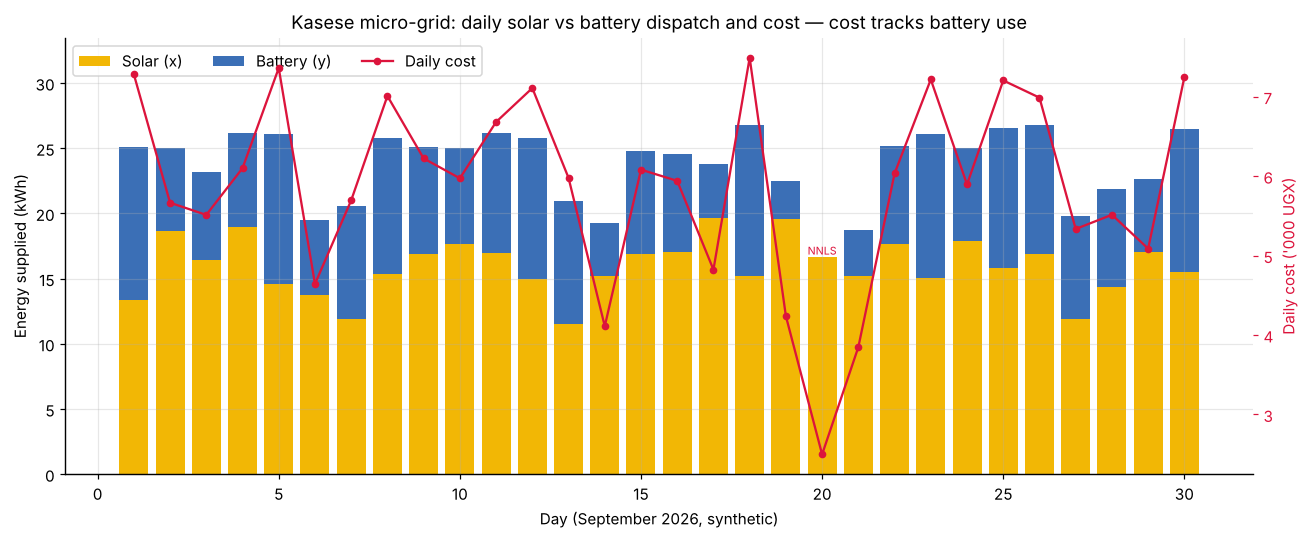

In [9]:
days = np.arange(1, D.shape[1] + 1)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(days, solar, color="#f2b705", label="Solar (x)")
ax.bar(days, battery, bottom=solar, color="#3b6fb6", label="Battery (y)")
for d in days[bad]:
    ax.annotate("NNLS", (d, solar[d-1] + battery[d-1]), ha="center", va="bottom", fontsize=7, color="crimson")
ax.set_xlabel("Day (September 2026, synthetic)"); ax.set_ylim(0, (solar + battery).max() * 1.25)
ax.set_ylabel("Energy supplied (kWh)")
ax2 = ax.twinx()
ax2.plot(days, daily_cost / 1000, "o-", color="crimson", lw=1.5, ms=4, label="Daily cost")
ax2.set_ylabel("Daily cost ('000 UGX)", color="crimson")
ax2.tick_params(axis="y", colors="crimson"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3)
ax.set_title("Kasese micro-grid: daily solar vs battery dispatch and cost — cost tracks battery use")
fig.tight_layout(); fig.savefig(FIG / "p2_dispatch_cost.png", bbox_inches="tight"); plt.show()

## Extension A — `HybridMicroGrid` with a diesel generator

Third source *z* (diesel, UGX 1,200/kWh, illustrative) and a third constraint for the **evening load**, when
solar is unavailable: 3y + 2z = D₃. The diesel term also enters the other two constraints.

In [10]:
hybrid = HybridMicroGrid()
print(hybrid, "\nA =\n", hybrid.A)
print(f"det = {hybrid.determinant():.2f}, cond = {hybrid.condition_number():.2f}")
print("Solve D = (50, 60, 30):", hybrid.solve_day(50, 60, 30).round(3))

# Linearly dependent third equation: row3 = row1 + row2
dependent = HybridMicroGrid([[3, 2, 1], [4, 1, 2], [7, 3, 3]])
print(f"\nDependent system: det = {dependent.determinant():.2e}, cond = {dependent.condition_number():.2e}")
try:
    dependent.solve_day(50, 60, 110)
except np.linalg.LinAlgError as e:
    print("Refused:", e)
print("Rank of dependent A:", np.linalg.matrix_rank(dependent.A))
print("Least-squares answer for consistent D3 = D1 + D2:", np.linalg.lstsq(dependent.A, [50, 60, 110], rcond=None)[0].round(3))

HybridMicroGrid(n_sources=3, det=-16) 
A =
 [[3. 2. 1.]
 [4. 1. 2.]
 [0. 3. 2.]]
det = -16.00, cond = 7.18
Solve D = (50, 60, 30): [10.625  6.25   5.625]

Dependent system: det = 1.11e-15, cond = 2.52e+16
Refused: System is singular or ill-conditioned (det=1.11e-15, cond=2.52e+16)
Rank of dependent A: 2
Least-squares answer for consistent D3 = D1 + D2: [11.316  5.789  4.474]


If the third equation is a linear combination of the others (here row 3 = row 1 + row 2), the matrix has rank 2
and determinant 0. Then either **no solution exists** (if D₃ ≠ D₁ + D₂ the constraints contradict each other) or
**infinitely many** exist (if D₃ = D₁ + D₂ the third equation adds no information and one degree of freedom is
free). The condition number explodes towards infinity, so `HybridMicroGrid` refuses to solve; `lstsq` returns one
of the infinitely many solutions (the minimum-norm one), which is mathematically valid but not a unique dispatch.
In practice the third constraint must describe a genuinely independent physical requirement.

## Extension B — Monte Carlo sensitivity (±5 % demand, 1,000 draws)

Base dispatch: x = 14.40, y = 8.40
x: sd = 0.84 kWh  (5.9% of base)
y: sd = 1.80 kWh  (21.4% of base)
Share of draws with y < 0: 0.0%
Error amplification ‖Δsol‖/‖sol‖ ÷ ‖ΔD‖/‖D‖: median 4.30, max 5.78 (bound = cond(A) = 5.83)


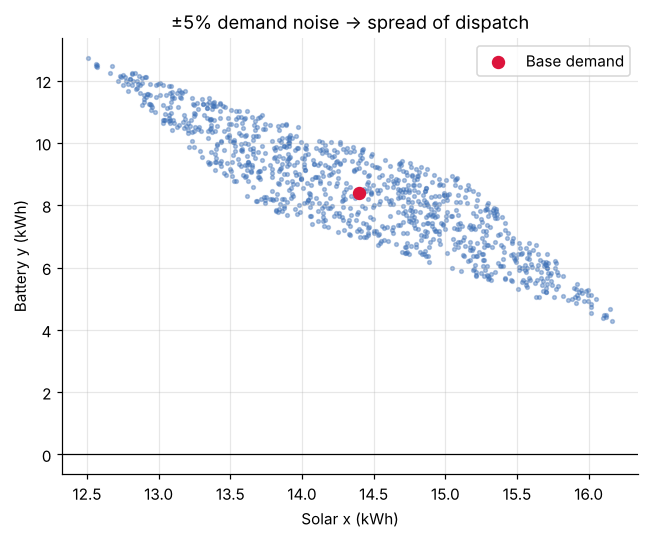

In [11]:
base_D = np.array([60.0, 66.0])
base_sol = grid.solve_day(*base_D)
mc_rng = np.random.default_rng(SEED)
draws = base_D[:, None] * mc_rng.uniform(0.95, 1.05, size=(2, 1000))
mc = grid.solve_vectorised(draws)
rel_in = np.linalg.norm(draws - base_D[:, None], axis=0) / np.linalg.norm(base_D)
rel_out = np.linalg.norm(mc - base_sol[:, None], axis=0) / np.linalg.norm(base_sol)
amp = rel_out / rel_in
print(f"Base dispatch: x = {base_sol[0]:.2f}, y = {base_sol[1]:.2f}")
print(f"x: sd = {mc[0].std(ddof=1):.2f} kWh  ({mc[0].std(ddof=1)/base_sol[0]:.1%} of base)")
print(f"y: sd = {mc[1].std(ddof=1):.2f} kWh  ({mc[1].std(ddof=1)/base_sol[1]:.1%} of base)")
print(f"Share of draws with y < 0: {(mc[1] < 0).mean():.1%}")
print(f"Error amplification ‖Δsol‖/‖sol‖ ÷ ‖ΔD‖/‖D‖: median {np.median(amp):.2f}, max {amp.max():.2f} "
      f"(bound = cond(A) = {grid.condition_number():.2f})")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(mc[0], mc[1], s=6, alpha=0.4, color="#3b6fb6")
ax.scatter(*base_sol, color="crimson", s=60, label="Base demand")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Solar x (kWh)"); ax.set_ylabel("Battery y (kWh)")
ax.set_title("±5% demand noise → spread of dispatch"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "p2_sensitivity.png", bbox_inches="tight"); plt.show()

## Findings & Limitations

**Findings.** The dispatch system is well-posed: det(A) = −5 and cond(A) ≈ 5.8, so every demand pair has one
unique answer and measurement error is amplified at most ~6×. The Monte Carlo test confirms this empirically:
±5 % demand noise produced a median amplification of 4.3 and a maximum of 5.8 — the condition number is a tight,
practical bound here, not just theory. But the amplification is **uneven**: solar moved by ~6 % while the battery
moved by ~21 %. The battery is the residual source — it absorbs the gap between two noisy loads — so it is the
most volatile (CV 0.37 vs 0.13 for solar) and also the most expensive: it supplies a third of the energy but
~59 % of the UGX 177,000 monthly cost.

Only one of 30 days (day 20) was physically infeasible; there the critical load was 1.35 × the daytime load, above
the 4/3 limit that the equations allow. NNLS repaired it with a 0.64 kWh mismatch, i.e. the grid could not meet
both constraints exactly and a third source is needed on such days. Vectorising the 30-day solve was ~14× faster
than looping, because A is factorised once.

**Limitations.** Demand is synthetic, and modelling dispatch as two *equalities* is unrealistic — real
operation has inequalities (battery state-of-charge, panel capacity, weather) and is a linear-programming
problem that minimises cost subject to those limits. Costs are illustrative and ignore capital and battery
degradation. The infeasible-day rule depends on the assumed D₂/D₁ ratio of 1.1; a different ratio would change
how often it happens. Day-to-day storage (battery charge carried over) is ignored entirely.